# Visualização das métricas de kills

Comparação dos resultados salvos nos CSVs desta pasta. As métricas se referem ao conjunto de **validação**; menor MAE e RMSE indicam menor erro. A comparação geral usa validação; os resultados de teste disponíveis para o KNN aparecem em uma seção separada.

Execute as células em ordem após atualizar os CSVs. Dependências: `pandas` e `matplotlib` (incluídas em `requirements.txt`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

arquivos = {
    'baseline': 'baseline_kills.csv',
    'modelos': 'regressao_linear_kills.csv',
    'busca': 'regressao_linear_busca.csv',
    'coeficientes': 'regressao_linear_coeficientes.csv',
    'arvore': 'arvore_decisao_kills.csv',
    'busca_arvore': 'arvore_decisao_busca.csv',
    'importancias_arvore': 'arvore_decisao_importancias.csv',
    'busca_knn': 'resultados_validacao_knn.csv',
    'final_knn': 'metricas_finais_knn.csv',
    'resumo_knn': 'resumo_knn_baseline.csv',
}

# Aceita notebooks iniciados na raiz do projeto ou dentro de results/metrics.
candidatos = (
    pasta
    for base in (Path.cwd(), *Path.cwd().parents)
    for pasta in (base, base / 'results' / 'metrics')
)
pasta_metricas = next(
    (pasta for pasta in candidatos if all((pasta / nome).is_file() for nome in arquivos.values())),
    None,
)
if pasta_metricas is None:
    raise FileNotFoundError('CSV não encontrado. Abra o notebook na raiz do projeto ou em results/metrics.')

dados = {chave: pd.read_csv(pasta_metricas / nome) for chave, nome in arquivos.items()}
#display(Markdown(f'**Arquivos lidos de:** `{pasta_metricas}`'))
display(pd.DataFrame({'arquivo': list(arquivos.values()), 'linhas': [len(dados[chave]) for chave in arquivos]}))

,arquivo,linhas
0,baseline_kills.csv,4
1,regressao_linear_kills.csv,2
2,regressao_linear_busca.csv,8
3,regressao_linear_coeficientes.csv,25
4,arvore_decisao_kills.csv,1
5,arvore_decisao_busca.csv,40
6,arvore_decisao_importancias.csv,25
7,resultados_validacao_knn.csv,39
8,metricas_finais_knn.csv,1
9,resumo_knn_baseline.csv,2


## Baseline

MAE e RMSE das quatro regras de baseline no conjunto de validação. Quanto menor o valor, menor o erro de previsão.

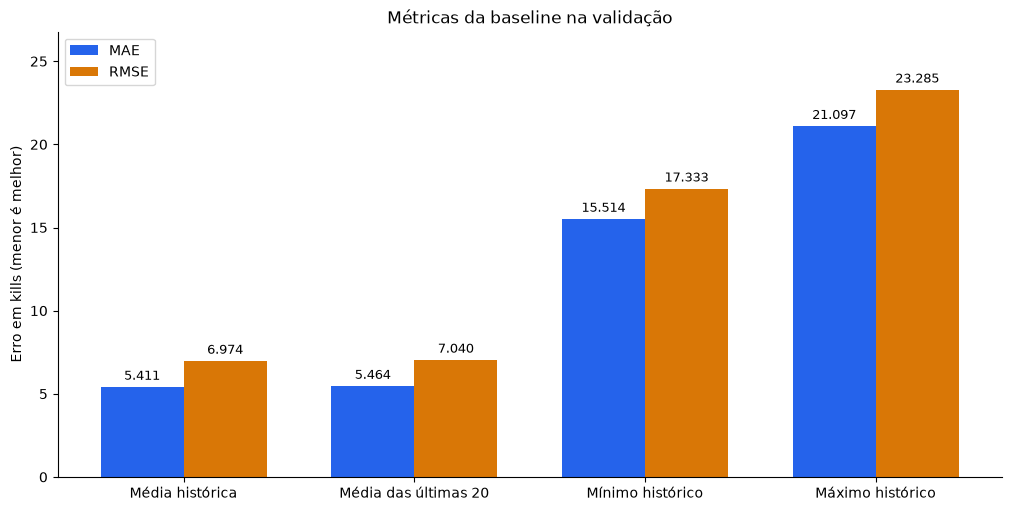

In [2]:
rotulos_baseline = {
    'media': 'Média histórica',
    'media_20': 'Média das últimas 20',
    'minimo': 'Mínimo histórico',
    'maximo': 'Máximo histórico',
}
baseline_vis = dados['baseline'].query("conjunto == 'validacao'").copy()
baseline_vis['Regra'] = baseline_vis['regra'].map(rotulos_baseline).fillna(baseline_vis['regra'])
posicoes = list(range(len(baseline_vis)))
largura = 0.36

fig, eixo = plt.subplots(figsize=(10, 5), layout='constrained')
barras_mae = eixo.bar([x - largura / 2 for x in posicoes], baseline_vis['MAE'], largura, label='MAE', color='#2563eb')
barras_rmse = eixo.bar([x + largura / 2 for x in posicoes], baseline_vis['RMSE'], largura, label='RMSE', color='#d97706')
eixo.set_xticks(posicoes, baseline_vis['Regra'])
eixo.set_ylabel('Erro em kills (menor é melhor)')
eixo.set_title('Métricas da baseline na validação')
eixo.set_ylim(0, baseline_vis[['MAE', 'RMSE']].to_numpy().max() * 1.15)
eixo.bar_label(barras_mae, fmt='%.3f', padding=3, fontsize=9)
eixo.bar_label(barras_rmse, fmt='%.3f', padding=3, fontsize=9)
eixo.legend()
eixo.spines[['top', 'right']].set_visible(False)
plt.show()

## Comparação geral

O MAE compara os modelos na validação. O CSV do KNN não informa a quantidade de partidas nem RMSE e R² de validação, por isso esses campos ficam vazios. O R² dos baselines também não está disponível.

In [3]:
nomes_baseline = {
    'media': 'Média histórica',
    'media_20': 'Média das últimas 20',
    'minimo': 'Mínimo histórico',
    'maximo': 'Máximo histórico',
}
nomes_modelos = {
    'regressao_linear': 'Regressão linear',
    'ridge': 'Ridge',
    'arvore_decisao': 'Árvore de decisão',
}

baseline = dados['baseline'].query("conjunto == 'validacao'").copy()
modelos = pd.concat([dados['modelos'], dados['arvore']], ignore_index=True)
modelos = modelos.query("conjunto == 'validacao'").copy()
baseline['Método'] = baseline['regra'].map(nomes_baseline).fillna(baseline['regra'])
modelos['Método'] = modelos['modelo'].map(nomes_modelos).fillna(modelos['modelo'])
knn_final = dados['final_knn'].iloc[0]
linha_knn = pd.DataFrame([{'Método': 'KNN', 'partidas': pd.NA,
                           'MAE': knn_final['MAE_validacao'], 'RMSE': float('nan'), 'R2': float('nan')}])
comparacao = pd.concat(
    [baseline[['Método', 'partidas', 'MAE', 'RMSE']],
     modelos[['Método', 'partidas', 'MAE', 'RMSE', 'R2']],
     linha_knn],
    ignore_index=True,
).sort_values('MAE').reset_index(drop=True)
if comparacao['partidas'].dropna().nunique() != 1:
    raise ValueError('Os métodos com contagem informada usam números diferentes de partidas.')
display(comparacao.round({'MAE': 3, 'RMSE': 3, 'R2': 3}))

referencia = baseline.loc[baseline['regra'].eq('media'), 'MAE'].iloc[0]
for codigo in ['regressao_linear', 'arvore_decisao']:
    mae_modelo = modelos.loc[modelos['modelo'].eq(codigo), 'MAE'].iloc[0]
    display(Markdown(
        f'**{nomes_modelos[codigo]} vs. média histórica:** MAE {mae_modelo:.3f} vs. {referencia:.3f} '
        f'({referencia - mae_modelo:.3f} kill a menos por partida, em média; '
        f'{(referencia - mae_modelo) / referencia:.1%} de redução).'
    ))
mae_knn = float(knn_final['MAE_validacao'])
display(Markdown(
    f'**KNN vs. média histórica:** MAE {mae_knn:.3f} vs. {referencia:.3f} '
    f'({referencia - mae_knn:.3f} kill a menos por partida, em média; '
    f'{(referencia - mae_knn) / referencia:.1%} de redução).'
))

,Método,partidas,MAE,RMSE,R2
0,Regressão linear,25916,5.362,6.925,0.159
1,Ridge,25916,5.362,6.925,0.159
2,KNN,<NA>,5.377,NaN,NaN
3,Árvore de decisão,25916,5.393,6.963,0.150
4,Média histórica,25916,5.411,6.974,NaN
5,Média das últimas 20,25916,5.464,7.040,NaN
6,Mínimo histórico,25916,15.514,17.333,NaN
7,Máximo histórico,25916,21.097,23.285,NaN


**Regressão linear vs. média histórica:** MAE 5.362 vs. 5.411 (0.049 kill a menos por partida, em média; 0.9% de redução).

**Árvore de decisão vs. média histórica:** MAE 5.393 vs. 5.411 (0.018 kill a menos por partida, em média; 0.3% de redução).

**KNN vs. média histórica:** MAE 5.377 vs. 5.411 (0.034 kill a menos por partida, em média; 0.6% de redução).

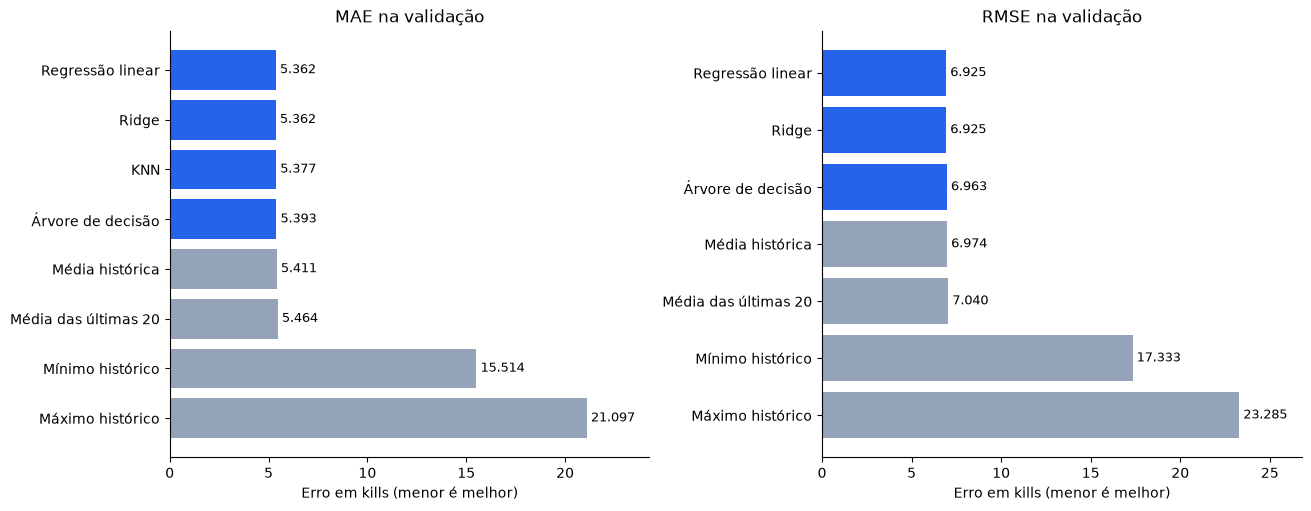

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for eixo, metrica in zip(eixos, ['MAE', 'RMSE']):
    dados_grafico = comparacao.dropna(subset=[metrica])
    cores = ['#2563eb' if metodo in (*nomes_modelos.values(), 'KNN') else '#94a3b8'
             for metodo in dados_grafico['Método']]
    barras = eixo.barh(dados_grafico['Método'], dados_grafico[metrica], color=cores)
    eixo.invert_yaxis()
    eixo.set_title(f'{metrica} na validação')
    eixo.set_xlabel('Erro em kills (menor é melhor)')
    eixo.set_xlim(0, comparacao[metrica].max() * 1.15)
    eixo.bar_label(barras, fmt='%.3f', padding=3, fontsize=9)
    eixo.spines[['top', 'right']].set_visible(False)
plt.show()

## Busca de `alpha` para Ridge

A regressão linear sem regularização (`alpha = 0`) serve de referência. O gráfico amplia a escala vertical para mostrar diferenças pequenas de MAE.

,Configuração,MAE_treino,MAE_validacao,RMSE_validacao,R2_validacao
0,Linear,5.313331,5.362004,6.924526,0.159004
1,Ridge 0.01,5.313331,5.362004,6.924526,0.159004
2,Ridge 0.1,5.313331,5.362006,6.924527,0.159003
3,Ridge 1,5.313330,5.362024,6.924539,0.159000
4,Ridge 10,5.313331,5.362171,6.924643,0.158975
5,Ridge 100,5.313479,5.362684,6.925011,0.158886
6,Ridge 1000,5.314268,5.363300,6.925517,0.158763
7,Ridge 10000,5.316015,5.365787,6.927375,0.158311


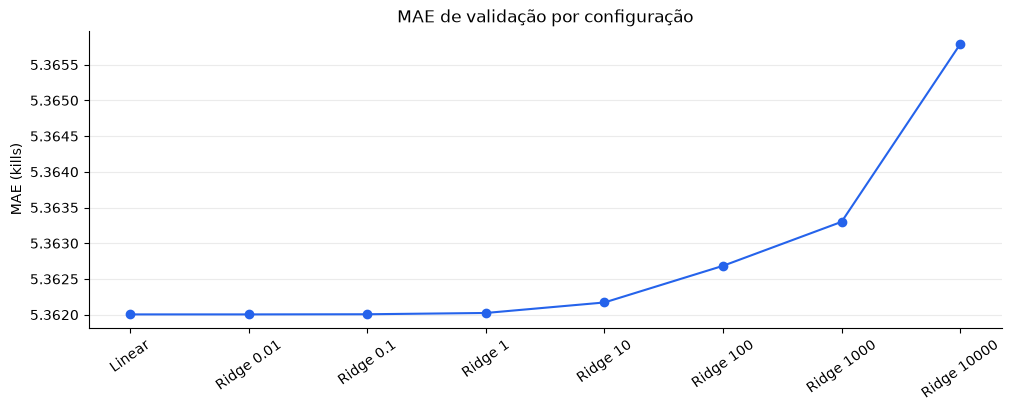

In [5]:
busca = dados['busca'].sort_values('alfa').copy()
busca['Configuração'] = busca.apply(
    lambda linha: 'Linear' if linha['modelo'] == 'regressao_linear' else f"Ridge {linha['alfa']:g}",
    axis=1,
)
display(busca[['Configuração', 'MAE_treino', 'MAE_validacao', 'RMSE_validacao', 'R2_validacao']])

fig, eixo = plt.subplots(figsize=(10, 4), layout='constrained')
eixo.plot(busca['Configuração'], busca['MAE_validacao'], marker='o', color='#2563eb')
eixo.set_title('MAE de validação por configuração')
eixo.set_ylabel('MAE (kills)')
eixo.tick_params(axis='x', rotation=35)
eixo.grid(axis='y', alpha=0.25)
eixo.spines[['top', 'right']].set_visible(False)
plt.show()

## Importância das features da árvore

A importância indica a contribuição de cada feature para a redução do erro dentro da árvore treinada. Não representa causalidade nem o efeito isolado da feature.

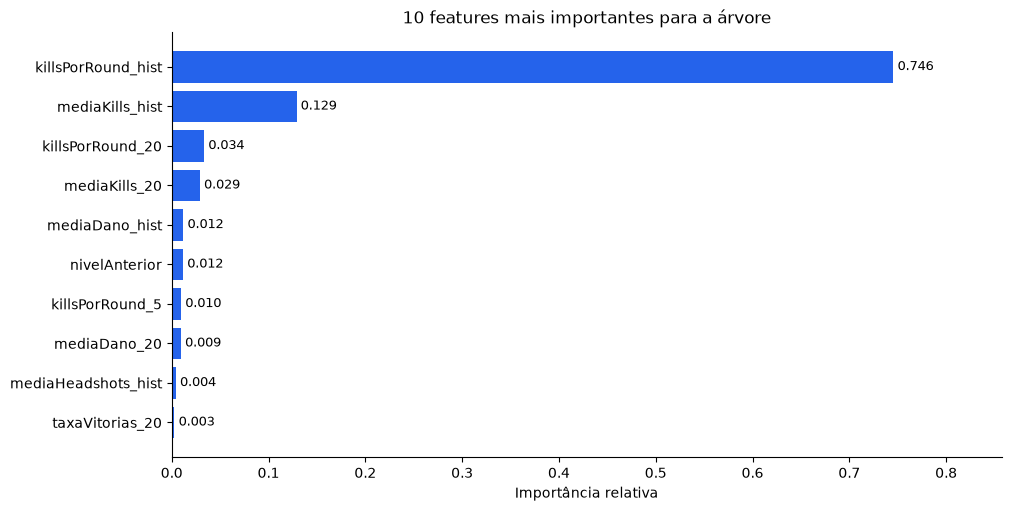

,feature,importancia
0,killsPorRound_hist,0.745516
1,mediaKills_hist,0.128930
2,killsPorRound_20,0.033515
3,mediaKills_20,0.029090
4,mediaDano_hist,0.011990
5,nivelAnterior,0.011724
6,killsPorRound_5,0.009701
7,mediaDano_20,0.009488
8,mediaHeadshots_hist,0.004258
9,taxaVitorias_20,0.002838


In [6]:
importancias = dados['importancias_arvore'].sort_values('importancia', ascending=False).copy()
principais_arvore = importancias.head(10).sort_values('importancia')

fig, eixo = plt.subplots(figsize=(10, 5), layout='constrained')
barras = eixo.barh(principais_arvore['feature'], principais_arvore['importancia'], color='#2563eb')
eixo.bar_label(barras, fmt='%.3f', padding=3, fontsize=9)
eixo.set_xlim(0, principais_arvore['importancia'].max() * 1.15)
eixo.set_xlabel('Importância relativa')
eixo.set_title('10 features mais importantes para a árvore')
eixo.spines[['top', 'right']].set_visible(False)
plt.show()
display(importancias)

## Busca de vizinhos e distância para o KNN

Cada linha mostra o MAE na validação para uma combinação de `K` e distância. Menor MAE é melhor; o conjunto de teste não participou da escolha.

,K,Distância,MAE_validacao
0,300,manhattan,5.3773
1,200,manhattan,5.3807
2,300,euclidean,5.3814
3,200,euclidean,5.3862
4,100,manhattan,5.3931
5,100,euclidean,5.4011
6,200,chebyshev,5.4230
7,50,manhattan,5.4235
8,300,chebyshev,5.4252
9,100,chebyshev,5.4283


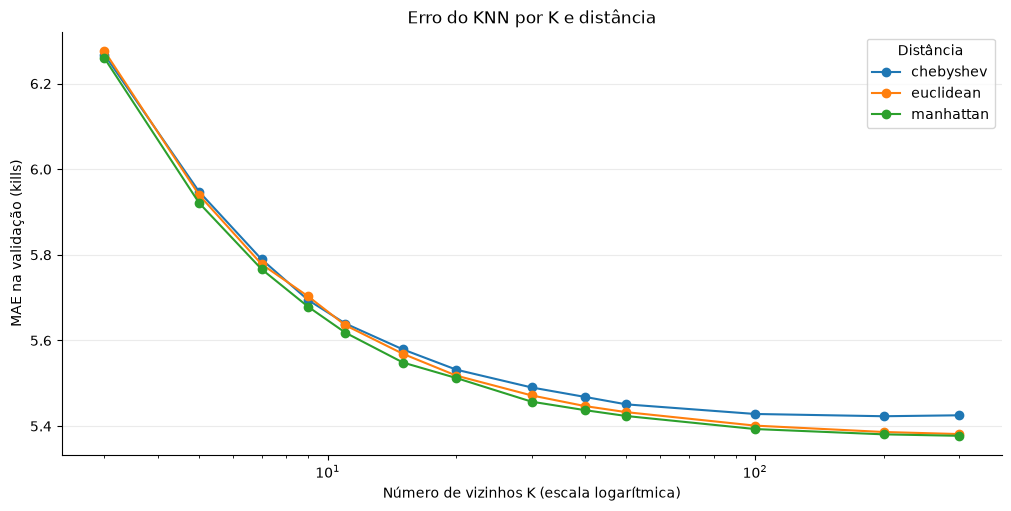

In [7]:
busca_knn = dados['busca_knn'].sort_values(['Distância', 'K']).copy()
display(busca_knn.sort_values('MAE_validacao').head(10))

fig, eixo = plt.subplots(figsize=(10, 5), layout='constrained')
for distancia, grupo in busca_knn.groupby('Distância'):
    eixo.plot(grupo['K'], grupo['MAE_validacao'], marker='o', label=distancia)
eixo.set_xscale('log')
eixo.set_xlabel('Número de vizinhos K (escala logarítmica)')
eixo.set_ylabel('MAE na validação (kills)')
eixo.set_title('Erro do KNN por K e distância')
eixo.grid(axis='y', alpha=0.25)
eixo.legend(title='Distância')
eixo.spines[['top', 'right']].set_visible(False)
plt.show()

## Resultado do KNN no teste

O teste foi usado após a escolha de `K = 300` e distância Manhattan na validação. Esta comparação inclui apenas KNN e sua baseline avaliados no teste; não deve ser misturada com a comparação geral de validação.

,modelo,K,distancia,MAE_validacao,MAE_teste,RMSE_teste,R2_teste
0,baseline (média histórica),NaN,NaN,5.4109,5.4123,7.0305,0.1289
1,KNN,300.0,manhattan,5.3773,5.3695,6.9737,0.1429


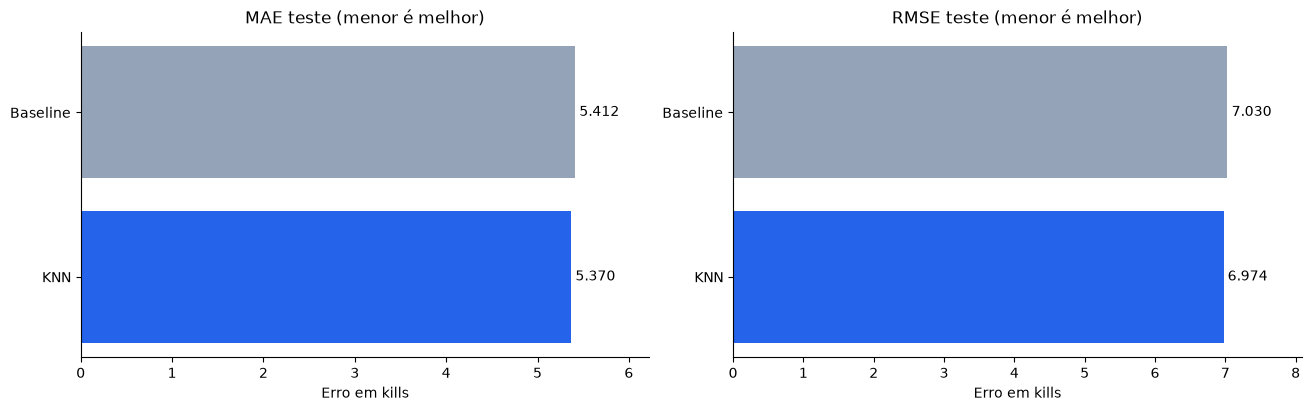

**KNN vs. baseline no teste:** redução de 0.043 kill no MAE (0.8%).

In [8]:
resumo_knn = dados['resumo_knn'][[
    'modelo', 'K', 'distancia', 'MAE_validacao', 'MAE_teste', 'RMSE_teste', 'R2_teste'
]].copy()
display(resumo_knn)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
rotulos_teste = resumo_knn['modelo'].replace({'baseline (média histórica)': 'Baseline'})
for eixo, metrica in zip(eixos, ['MAE_teste', 'RMSE_teste']):
    barras = eixo.barh(rotulos_teste, resumo_knn[metrica], color=['#94a3b8', '#2563eb'])
    eixo.invert_yaxis()
    eixo.bar_label(barras, fmt='%.3f', padding=3)
    eixo.set_xlim(0, resumo_knn[metrica].max() * 1.15)
    eixo.set_title(metrica.replace('_', ' ') + ' (menor é melhor)')
    eixo.set_xlabel('Erro em kills')
    eixo.spines[['top', 'right']].set_visible(False)
plt.show()

mae_baseline_teste = resumo_knn.loc[resumo_knn['modelo'].str.startswith('baseline'), 'MAE_teste'].iloc[0]
mae_knn_teste = resumo_knn.loc[resumo_knn['modelo'].eq('KNN'), 'MAE_teste'].iloc[0]
display(Markdown(
    f'**KNN vs. baseline no teste:** redução de {mae_baseline_teste - mae_knn_teste:.3f} '
    f'kill no MAE ({(mae_baseline_teste - mae_knn_teste) / mae_baseline_teste:.1%}).'
))